# Module Five Activity

For the module five activity, you will write Python code to create clear and informative data visualizations from the provided data set `Most-Recent-Cohorts-Field-of-Study.csv`. Your code should be well-organized and reflect a clear understanding of each step in the visualization process. 

<div class="alert alert-block alert-danger">
    <span style="color:black"><b><i>Note:</i></b> there are two parts to this assignment. Part One is the data visualization coding activity. Part Two is the reflection paper.</span>
</div>

Once your code is complete, you will download this notebook as an HTML file by clicking **File**, then **Download As**, then **HTML (.html)** from the Jupyter menu bar. Validate that your code, output, and all six visualizations (rendered as images using the display() function) are visible in the html file before submission.

<div class="alert alert-block alert-danger">
    <span style="color:black"><b><i>Missing Blocks:</i></b> Ensure that you have clicked <b><mark>Run</mark></b> for all blocks before downloading as an HTML file or the block may be missing from your submission. <b>Images</b> must be called using the <b><i>display()</i></b> function, for example: <b><mark>display(Image(filename="output/{image_name}.png"))</mark></b></span>
</div>

Specifically, you must address the items from the rubric criteria.

### Part One: Data Visualization

#### Prepare the given data set for visualization. Consider the following:  
- Are there any columns you can remove? 
- Are filters or groupings needed? 
- Are the data values structured for your chart types? 

#### Clean the given data set for visualization using Python. Consider the following:  
- Are there any missing or invalid values?  
- Are there any unclear column names? 
- Are the data types correct for each column (e.g., numeric, categorical, datetime)? 

#### Create multiple types of visualizations using Python.  Include the following: 
- Dendrogram 
- PCA scatterplot 
- Cluster size distribution 
- Feature importance heatmap 
- Trend chart 
- Scatterplot

<div class="alert alert-block alert-danger">
    <span style="color:black"><b><i>Note:</i></b> You will need to ensure that you have created at least one of each of the visual types listed above.</span>
</div>

### Part 2: Reflection
<i>This part is to be completed in a word document, using the output here to answer the topics.</i>

#### Identify patterns in the data. Consider the following:  
- Are there any clear trends, clusters, or outliers visible in your visualizations? 
- Are certain variables showing consistent behavior or relationships? 
- Are the patterns similar across different visualization types? 

#### Draw conclusions from the patterns. Consider the following:  
- Are your conclusions clearly based on the patterns you observed? 
- Are your findings supported by multiple visuals or data points? 


#### Explain how the visualizations validate your findings. Consider the following:  
- Are specific chart elements (e.g., color, scale, labels) helping to highlight your findings? 
- Are the insights you found something you could not easily see without the visuals? 

#### Write a summary of the visualization choices you made. Include the following:  
- An explanation of the types of charts you used 
- An explanation of the formatting decisions to support visual clarity

<div class="alert alert-block alert-success">
    <span style="color:black"><b><i>To Begin:</i></b> This Python template program has been broken down into segments as a guide for what steps you should do at a minimum to complete this activity. Look for the <b># To Do:</b> comments. These are placeholders for you to provide Python code segments. Fill out all <b># To Do:</b> code segments to complete this program.</span><br/><br/>
    <span style="color:black"><b><i>Once Complete:</i></b> Execute a "Kernel restart and run all" to verify that all your code works as a single unit by clicking <b>Kernel</b>, then <b>Restart & Run All</b> before downloading as html.</span>
</div>

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hint:</i></b> If you need to install additional packages, see one of the earlier modules on how to configure and call a requirements.txt file.</span>
</div>

## Import the Required Packages
- **pandas (pd):** For reading and manipulating the dataset.
- **MinMaxScaler:** A preprocessing tool from sklearn to normalize data values between 0 and 1.
- **PCA:** Principal Component Analysis (dimensionality reduction) from sklearn for visualizing clusters in 2D.
- **dendrogram, linkage, fcluster:** Tools from scipy for performing hierarchical clustering and visualizing its results.
- **matplotlib.pyplot (plt):** For creating charts and saving visuals.
- **seaborn (sns):** For advanced and visually appealing charts.
- **numpy (np):** For numerical operations like arrays and aggregations.

In [1]:
import pandas as pd   # for reading & manipulating the dataset
from sklearn.preprocessing import MinMaxScaler    # a preprocessing tool from sklearn to normalize data values
                                                                                    # between 0 and 1
from sklearn.decomposition import PCA  # Principal Component Analysis (dimensionality reduction) from 
                                                                   # sklearn for visualizing clusters in 2D
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster    # tools from scipy for performing hierarchical clustering & visualizing its results
import matplotlib.pyplot as plt     #  for creating charts & saving visuals
import seaborn as sns    #  for advanced & visually appealing charts
import numpy as np      # for numerical operations like arrays & aggregations

from IPython.display import Image, display # for image rendering in html output

# Part One: Data Visualization

## Loading the Data

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> Use <b><mark>pd.read_csv</mark></b> to read a CSV file and load it into a DataFrame (data). Use <b><mark>try block</mark></b> to ensures the program handles errors gracefully if the file cannot be loaded (e.g., missing or incorrect path). Use <b><mark>exit()</mark></b> to stop the program if an error occurs.</span>
</div>

In [2]:
print("Loading dataset...")

try:
    data = pd.read_csv(
        "data/Most-Recent-Cohorts-Field-of-Study.csv",
        low_memory=False
    )
    print("Dataset loaded successfully!")
    print("Dataset shape:", data.shape)

except (FileNotFoundError, pd.errors.ParserError) as e:
    print("Error loading dataset:", e)
    raise

Loading dataset...
Dataset loaded successfully!
Dataset shape: (229188, 174)


## Display Dataset Information

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> Use <b><mark>data.columns.tolist()</mark></b> to extract and print all column names. Use <b><mark>data.index.tolist()</mark></b> to show the index values of the dataset (e.g., row numbers). Use <b><mark>data.head()</mark></b> to display the top 5 rows to give an overview of the data.</span>
</div>

In [3]:
print("Column Names:")
print(data.columns.tolist())

Column Names:
['UNITID', 'OPEID6', 'INSTNM', 'CONTROL', 'MAIN', 'CIPCODE', 'CIPDESC', 'CREDLEV', 'CREDDESC', 'IPEDSCOUNT1', 'IPEDSCOUNT2', 'DEBT_ALL_STGP_ANY_N', 'DEBT_ALL_STGP_ANY_MEAN', 'DEBT_ALL_STGP_ANY_MDN', 'DEBT_ALL_STGP_EVAL_N', 'DEBT_ALL_STGP_EVAL_MEAN', 'DEBT_ALL_STGP_EVAL_MDN', 'DEBT_ALL_PP_ANY_N', 'DEBT_ALL_PP_ANY_MEAN', 'DEBT_ALL_PP_ANY_MDN', 'DEBT_ALL_PP_EVAL_N', 'DEBT_ALL_PP_EVAL_MEAN', 'DEBT_ALL_PP_EVAL_MDN', 'DEBT_MALE_STGP_ANY_N', 'DEBT_MALE_STGP_ANY_MEAN', 'DEBT_MALE_STGP_ANY_MDN', 'DEBT_MALE_STGP_EVAL_N', 'DEBT_MALE_STGP_EVAL_MEAN', 'DEBT_MALE_STGP_EVAL_MDN', 'DEBT_MALE_PP_ANY_N', 'DEBT_MALE_PP_ANY_MEAN', 'DEBT_MALE_PP_ANY_MDN', 'DEBT_MALE_PP_EVAL_N', 'DEBT_MALE_PP_EVAL_MEAN', 'DEBT_MALE_PP_EVAL_MDN', 'DEBT_NOTMALE_STGP_ANY_N', 'DEBT_NOTMALE_STGP_ANY_MEAN', 'DEBT_NOTMALE_STGP_ANY_MDN', 'DEBT_NOTMALE_STGP_EVAL_N', 'DEBT_NOTMALE_STGP_EVAL_MEAN', 'DEBT_NOTMALE_STGP_EVAL_MDN', 'DEBT_NOTMALE_PP_ANY_N', 'DEBT_NOTMALE_PP_ANY_MEAN', 'DEBT_NOTMALE_PP_ANY_MDN', 'DEBT_NOTMALE_

In [4]:
print("Row Index Labels:")
print(data.index.tolist()[:20])
print("Total number of rows:", len(data.index))

Row Index Labels:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Total number of rows: 229188


In [5]:
print("First 5 Rows of the Dataset:")
display(data.head())

First 5 Rows of the Dataset:


,UNITID,OPEID6,INSTNM,CONTROL,MAIN,CIPCODE,CIPDESC,CREDLEV,CREDDESC,IPEDSCOUNT1,...,EARN_COUNT_PELL_WNE_5YR,EARN_PELL_WNE_MDN_5YR,EARN_COUNT_NOPELL_WNE_5YR,EARN_NOPELL_WNE_MDN_5YR,EARN_COUNT_MALE_WNE_5YR,EARN_MALE_WNE_MDN_5YR,EARN_COUNT_NOMALE_WNE_5YR,EARN_NOMALE_WNE_MDN_5YR,EARN_COUNT_HIGH_CRED_5YR,EARN_IN_STATE_5YR
0,100654.0,1002,Alabama A & M University,Public,1,100,"Agriculture, General.",3,Bachelor's Degree,NaN,...,PS,PS,PS,PS,PS,PS,PS,PS,PS,PS
1,100654.0,1002,Alabama A & M University,Public,1,101,Agricultural Business and Management.,3,Bachelor's Degree,NaN,...,PS,PS,PS,PS,PS,PS,PS,PS,PS,PS
2,100654.0,1002,Alabama A & M University,Public,1,109,Animal Sciences.,3,Bachelor's Degree,3.0,...,PS,PS,PS,PS,PS,PS,PS,PS,PS,PS
3,100654.0,1002,Alabama A & M University,Public,1,110,Food Science and Technology.,3,Bachelor's Degree,7.0,...,PS,PS,PS,PS,PS,PS,PS,PS,PS,PS
4,100654.0,1002,Alabama A & M University,Public,1,110,Food Science and Technology.,5,Master's Degree,4.0,...,PS,PS,PS,PS,PS,PS,PS,PS,PS,PS


## Inspect and Select Numeric Columns

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> Use <b><mark>select_dtypes()</mark></b> to filter columns with numeric data types (float64 and int64). Removes columns like <b><mark>UNITID</mark></b> and <b><mark>OPEID6</mark></b>, which are not useful for clustering. Use <b><mark>dropna()</mark></b> to remove rows with missing values to clean data for clustering, see also module three sample for additional cleaning examples. Use error handling <b><mark>try blocks</mark></b> to ensures the program stops if the column selection fails.</span>
</div>

In [6]:
print("Inspecting dataset to select numeric columns for clustering...")

try:
    # Remove identifier columns that are not useful for clustering
    data_clean = data.drop(
        columns=["UNITID", "OPEID6"],
        errors="ignore"
    ).copy()

    # Convert numeric-looking text to numbers.
    # Suppressed values such as "PS" become missing values.
    for col in data_clean.columns:
        if data_clean[col].dtype == "object":
            converted = pd.to_numeric(data_clean[col], errors="coerce")
            if converted.notna().sum() > 0 and (
                converted.notna().sum() >=
                data_clean[col].notna().sum() * 0.5
            ):
                data_clean[col] = converted

    # Keep numeric columns and remove columns with no variation
    numeric_data = data_clean.select_dtypes(
        include=[np.number]
    )
    numeric_data = numeric_data.replace(
        [np.inf, -np.inf], np.nan
    )
    numeric_data = numeric_data.loc[
        :, numeric_data.nunique(dropna=True) > 1
    ]

    # Use columns with sufficient available data
    numeric_data = numeric_data.loc[
        :, numeric_data.notna().mean() >= 0.5
    ]

    # Remove rows with missing values
    numeric_data = numeric_data.dropna()

    if numeric_data.empty or numeric_data.shape[1] < 2:
        raise ValueError("Not enough complete numeric data for clustering.")

    print("Numeric columns selected:")
    print(numeric_data.columns.tolist())
    print("Cleaned dataset shape:", numeric_data.shape)
    print("Missing values:", numeric_data.isna().sum().sum())

except (ValueError, TypeError, KeyError) as e:
    print("Error preparing numeric data:", e)
    raise


Inspecting dataset to select numeric columns for clustering...
Numeric columns selected:
['MAIN', 'CIPCODE', 'CREDLEV', 'IPEDSCOUNT1', 'IPEDSCOUNT2', 'EARN_COUNT_NWNE_HI_1YR', 'EARN_COUNT_NWNE_1YR', 'EARN_COUNT_NWNE_4YR', 'DISTANCE', 'EARN_COUNT_NWNE_5YR']
Cleaned dataset shape: (103957, 10)
Missing values: 0


## Normalize the Data

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> Use <b><mark>MinMaxScaler()</mark></b> to scale data values between 0 and 1, ensuring all features are on the same scale. Use <b><mark>fit_transform()</mark></b> to fit the scaler to the data and transform it.</span>
</div>

In [7]:
print("Normalizing the data using MinMaxScaler...")

try:
    # Initialize the MinMaxScaler
    scaler = MinMaxScaler()

    # Normalize all selected numeric features between 0 and 1
    normalized_data = scaler.fit_transform(numeric_data)

    # Convert the normalized data back into a DataFrame
    normalized_df = pd.DataFrame(
        normalized_data,
        columns=numeric_data.columns,
        index=numeric_data.index
    )

    print("Data normalized successfully!")
    print("Normalized dataset shape:", normalized_df.shape)
    print("Minimum normalized value:", normalized_df.min().min())
    print("Maximum normalized value:", normalized_df.max().max())

except (ValueError, TypeError) as e:
    print("Error normalizing data:", e)
    raise


Normalizing the data using MinMaxScaler...
Data normalized successfully!
Normalized dataset shape: (103957, 10)
Minimum normalized value: 0.0
Maximum normalized value: 1.0


## Perform Hierarchical Clustering

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> Use <b><mark>linkage()</mark></b> to compute hierarchical clusters using <b><mark>Ward's</mark></b> method, which minimizes variance between clusters. Limit clustering to the first 1000 rows for performance. Use <b><mark>fcluster()</mark></b> to assign cluster labels to data points based on the number of clusters (max_clusters).</span>
</div>

In [8]:
print("Performing hierarchical clustering using Ward's method...")

try:
    # Limit the data to 1,000 rows for performance
    sample_data = normalized_df.iloc[:1000].copy()

    # Perform hierarchical clustering using Ward's method
    linked = linkage(sample_data, method="ward")

    # Set the number of clusters
    max_clusters = 4

    # Assign each record to a cluster
    cluster_labels = fcluster(
        linked,
        t=max_clusters,
        criterion="maxclust"
    )

    # Store cluster labels with the sampled data
    clustered_data = sample_data.copy()
    clustered_data["Cluster"] = cluster_labels

    print("Hierarchical clustering completed successfully!")
    print("Number of records clustered:", len(sample_data))
    print("Number of clusters:", len(np.unique(cluster_labels)))

    print("\nCluster Size Distribution:")
    print(clustered_data["Cluster"].value_counts().sort_index())

except (ValueError, TypeError) as e:
    print("Error performing hierarchical clustering:", e)
    raise

Performing hierarchical clustering using Ward's method...
Hierarchical clustering completed successfully!
Number of records clustered: 1000
Number of clusters: 4

Cluster Size Distribution:
Cluster
1     38
2    201
3    365
4    396
Name: count, dtype: int64


## Generate, Save, and Output Visualizations

Each visualization is created, saved and displayed, with text output provided before and after.

### Dendrogram

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> A dendrogram displays the hierarchical structure of clusters. Save the image as <b><mark>dendrogram.png</mark></b>. Use <b><mark>display()</mark></b> to render the image for html file output. Do not use an <mark>html image</mark> tag in the markdown, or the image will not print in the html download.</span>
</div>

In [9]:

print("Creating dendrogram to visualize hierarchical clustering...")

try:
    import os

    # Ensure the output folder exists
    os.makedirs("output", exist_ok=True)

    # Create the dendrogram
    plt.figure(figsize=(14, 7))

    dendrogram(
        linked,
        truncate_mode="lastp",
        p=30,
        show_leaf_counts=True,
        leaf_rotation=45,
        leaf_font_size=9
    )

    # Add chart labels and formatting
    plt.title("Hierarchical Clustering Dendrogram", fontsize=16)
    plt.xlabel("Grouped Records / Cluster Nodes", fontsize=12)
    plt.ylabel("Ward Linkage Distance", fontsize=12)
    plt.tight_layout()

    # Save the visualization
    plt.savefig("output/dendrogram.png", dpi=300, bbox_inches="tight")
    plt.close()

    print("Dendrogram saved successfully!")

except (ValueError, OSError) as e:
    print("Error creating dendrogram:", e)
    raise

Creating dendrogram to visualize hierarchical clustering...
Dendrogram saved successfully!


Dendrogram visualization display...


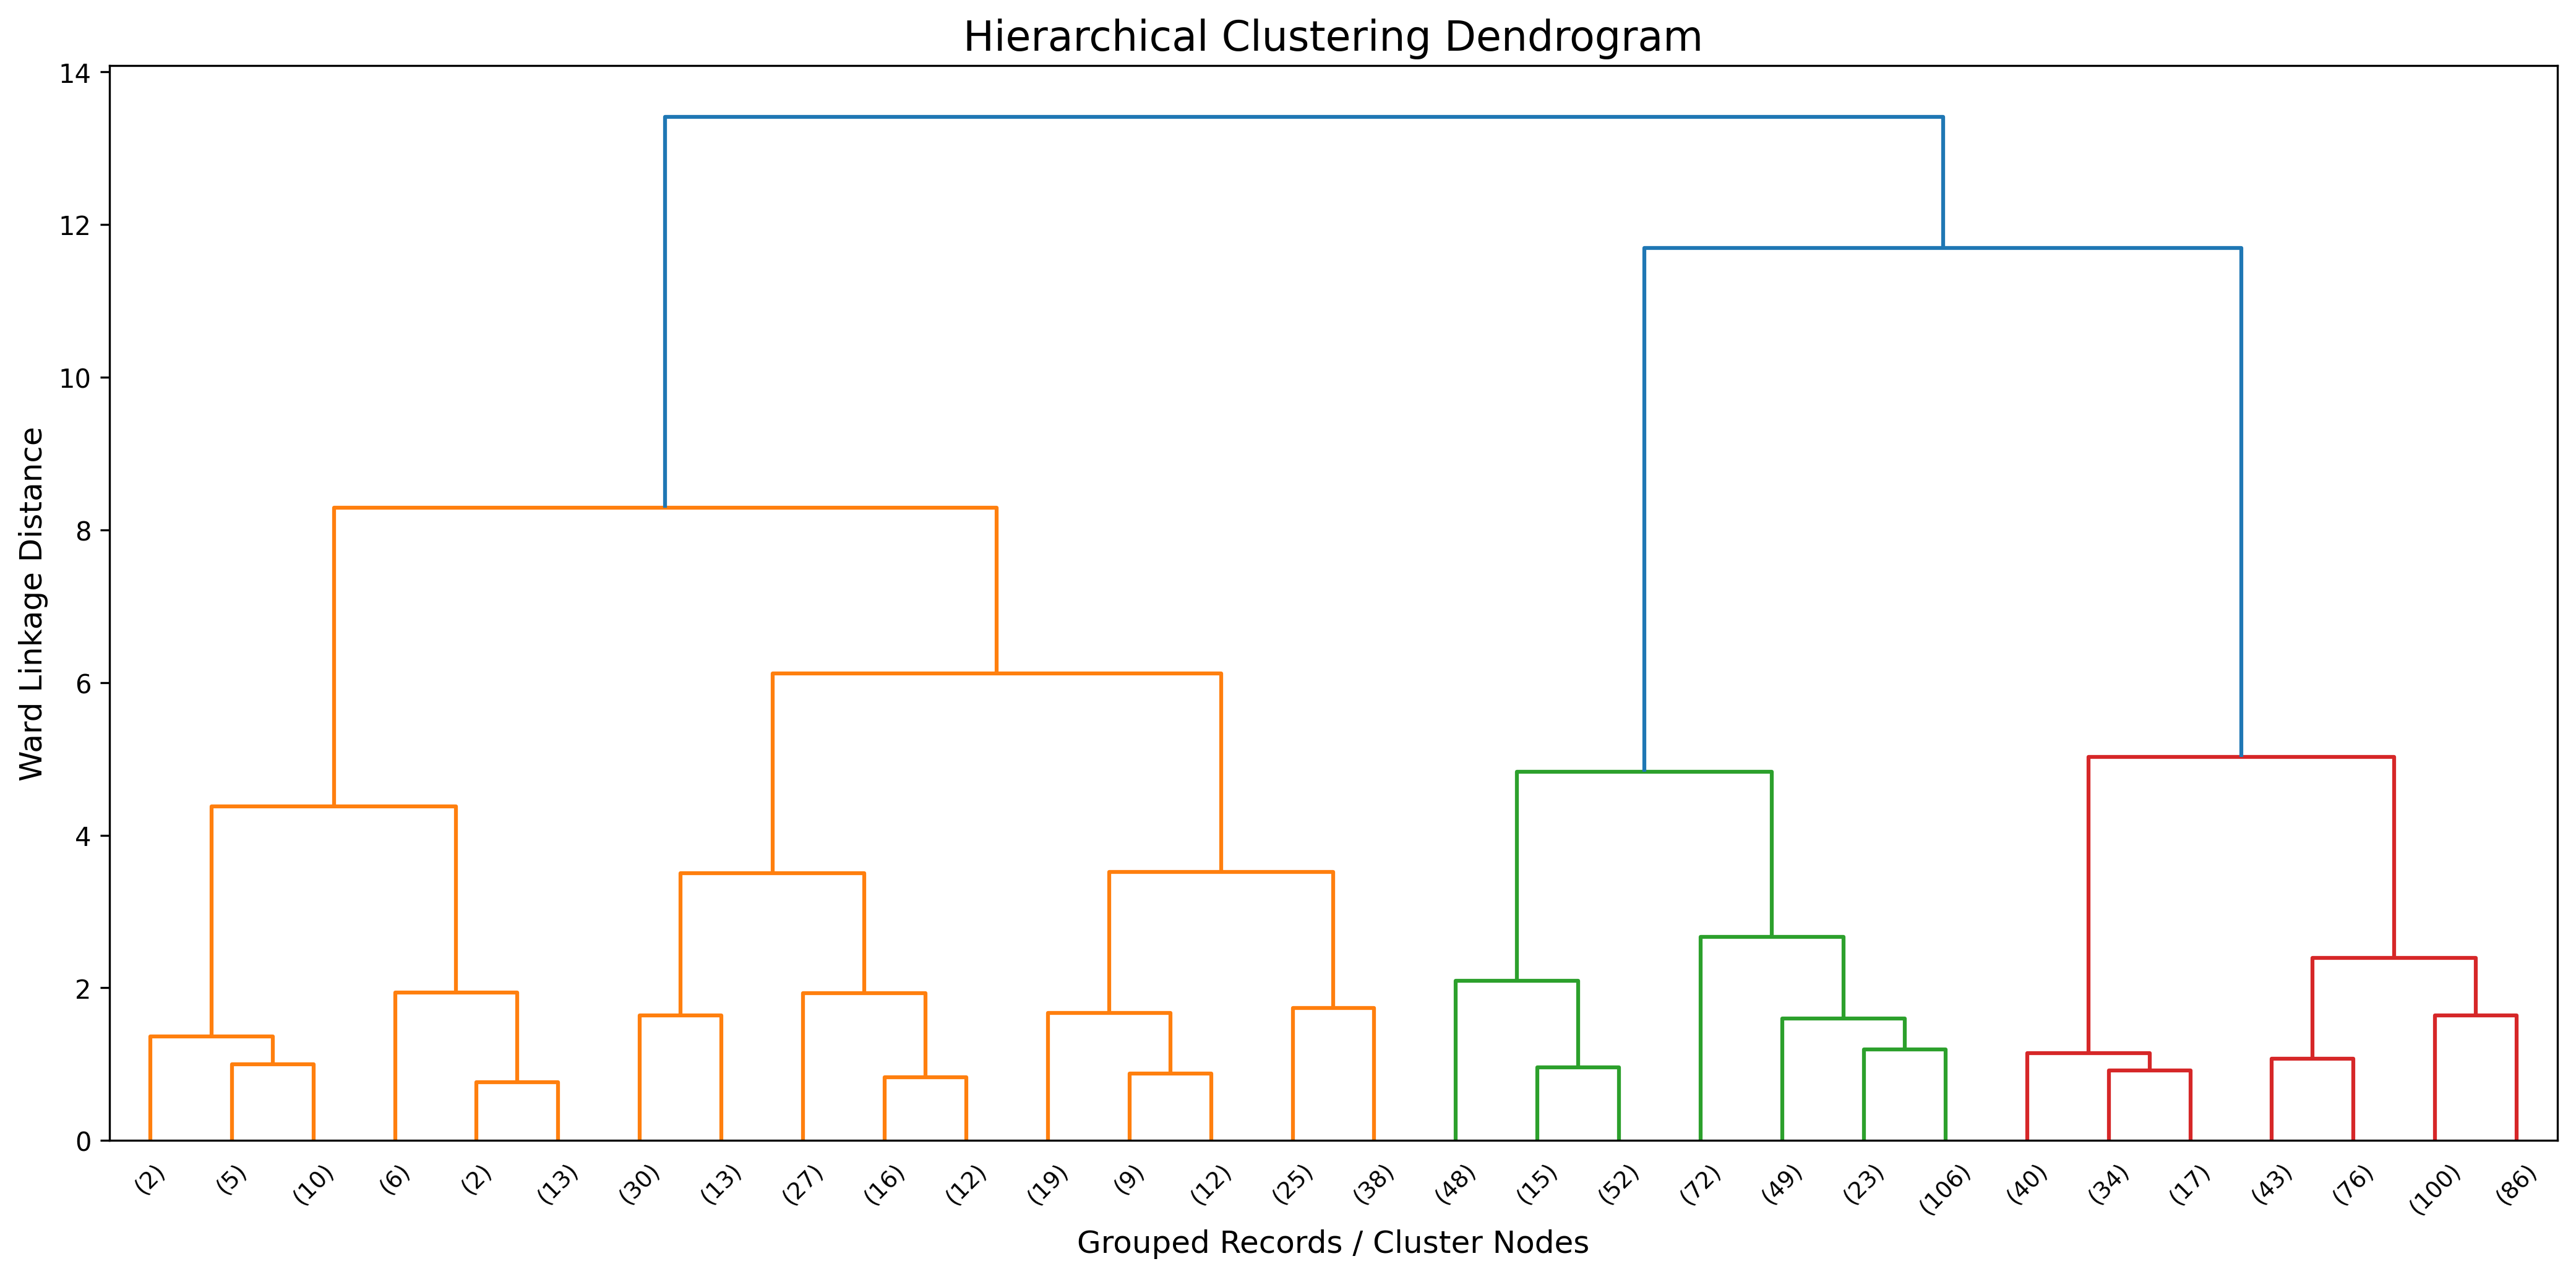

In [10]:

print("Dendrogram visualization display...")

display(Image(filename="output/dendrogram.png"))

### PCA Scatter Plot

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> A PCA scatter plot projects high-dimensional data into 2D using PCA for visualization. Save the image as <b><mark>pca_scatter_plot.png</mark></b>. Use <b><mark>display()</mark></b> to render the image for html file output. Do not use an <mark>html image</mark> tag in the markdown, or the image will not print in the html download.</span>
</div>

In [11]:
print("Creating scatter plot (PCA Reduced) to visualize clusters in 2D...")

try:
    # Reduce the normalized data to two principal components
    pca = PCA(n_components=2)
    pca_results = pca.fit_transform(sample_data)

    # Store the PCA results and cluster labels
    pca_df = pd.DataFrame({
        "PC1": pca_results[:, 0],
        "PC2": pca_results[:, 1],
        "Cluster": cluster_labels.astype(str)
    })

    # Create the PCA scatterplot
    plt.figure(figsize=(12, 8))

    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue="Cluster",
        palette="Set2",
        s=65,
        alpha=0.8
    )

    # Add labels and formatting
    plt.title("PCA Scatterplot of Hierarchical Clusters", fontsize=16)
    plt.xlabel(
        f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} Variance)"
    )
    plt.ylabel(
        f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} Variance)"
    )
    plt.legend(title="Cluster")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    # Save the visualization
    plt.savefig(
        "output/pca_scatter_plot.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    print("PCA scatterplot saved successfully!")
    print(
        "Total explained variance:",
        f"{pca.explained_variance_ratio_.sum():.2%}"
    )

except (ValueError, TypeError, OSError) as e:
    print("Error creating PCA scatterplot:", e)
    raise

Creating scatter plot (PCA Reduced) to visualize clusters in 2D...
PCA scatterplot saved successfully!
Total explained variance: 75.09%


PCA scatter plot visualization display...


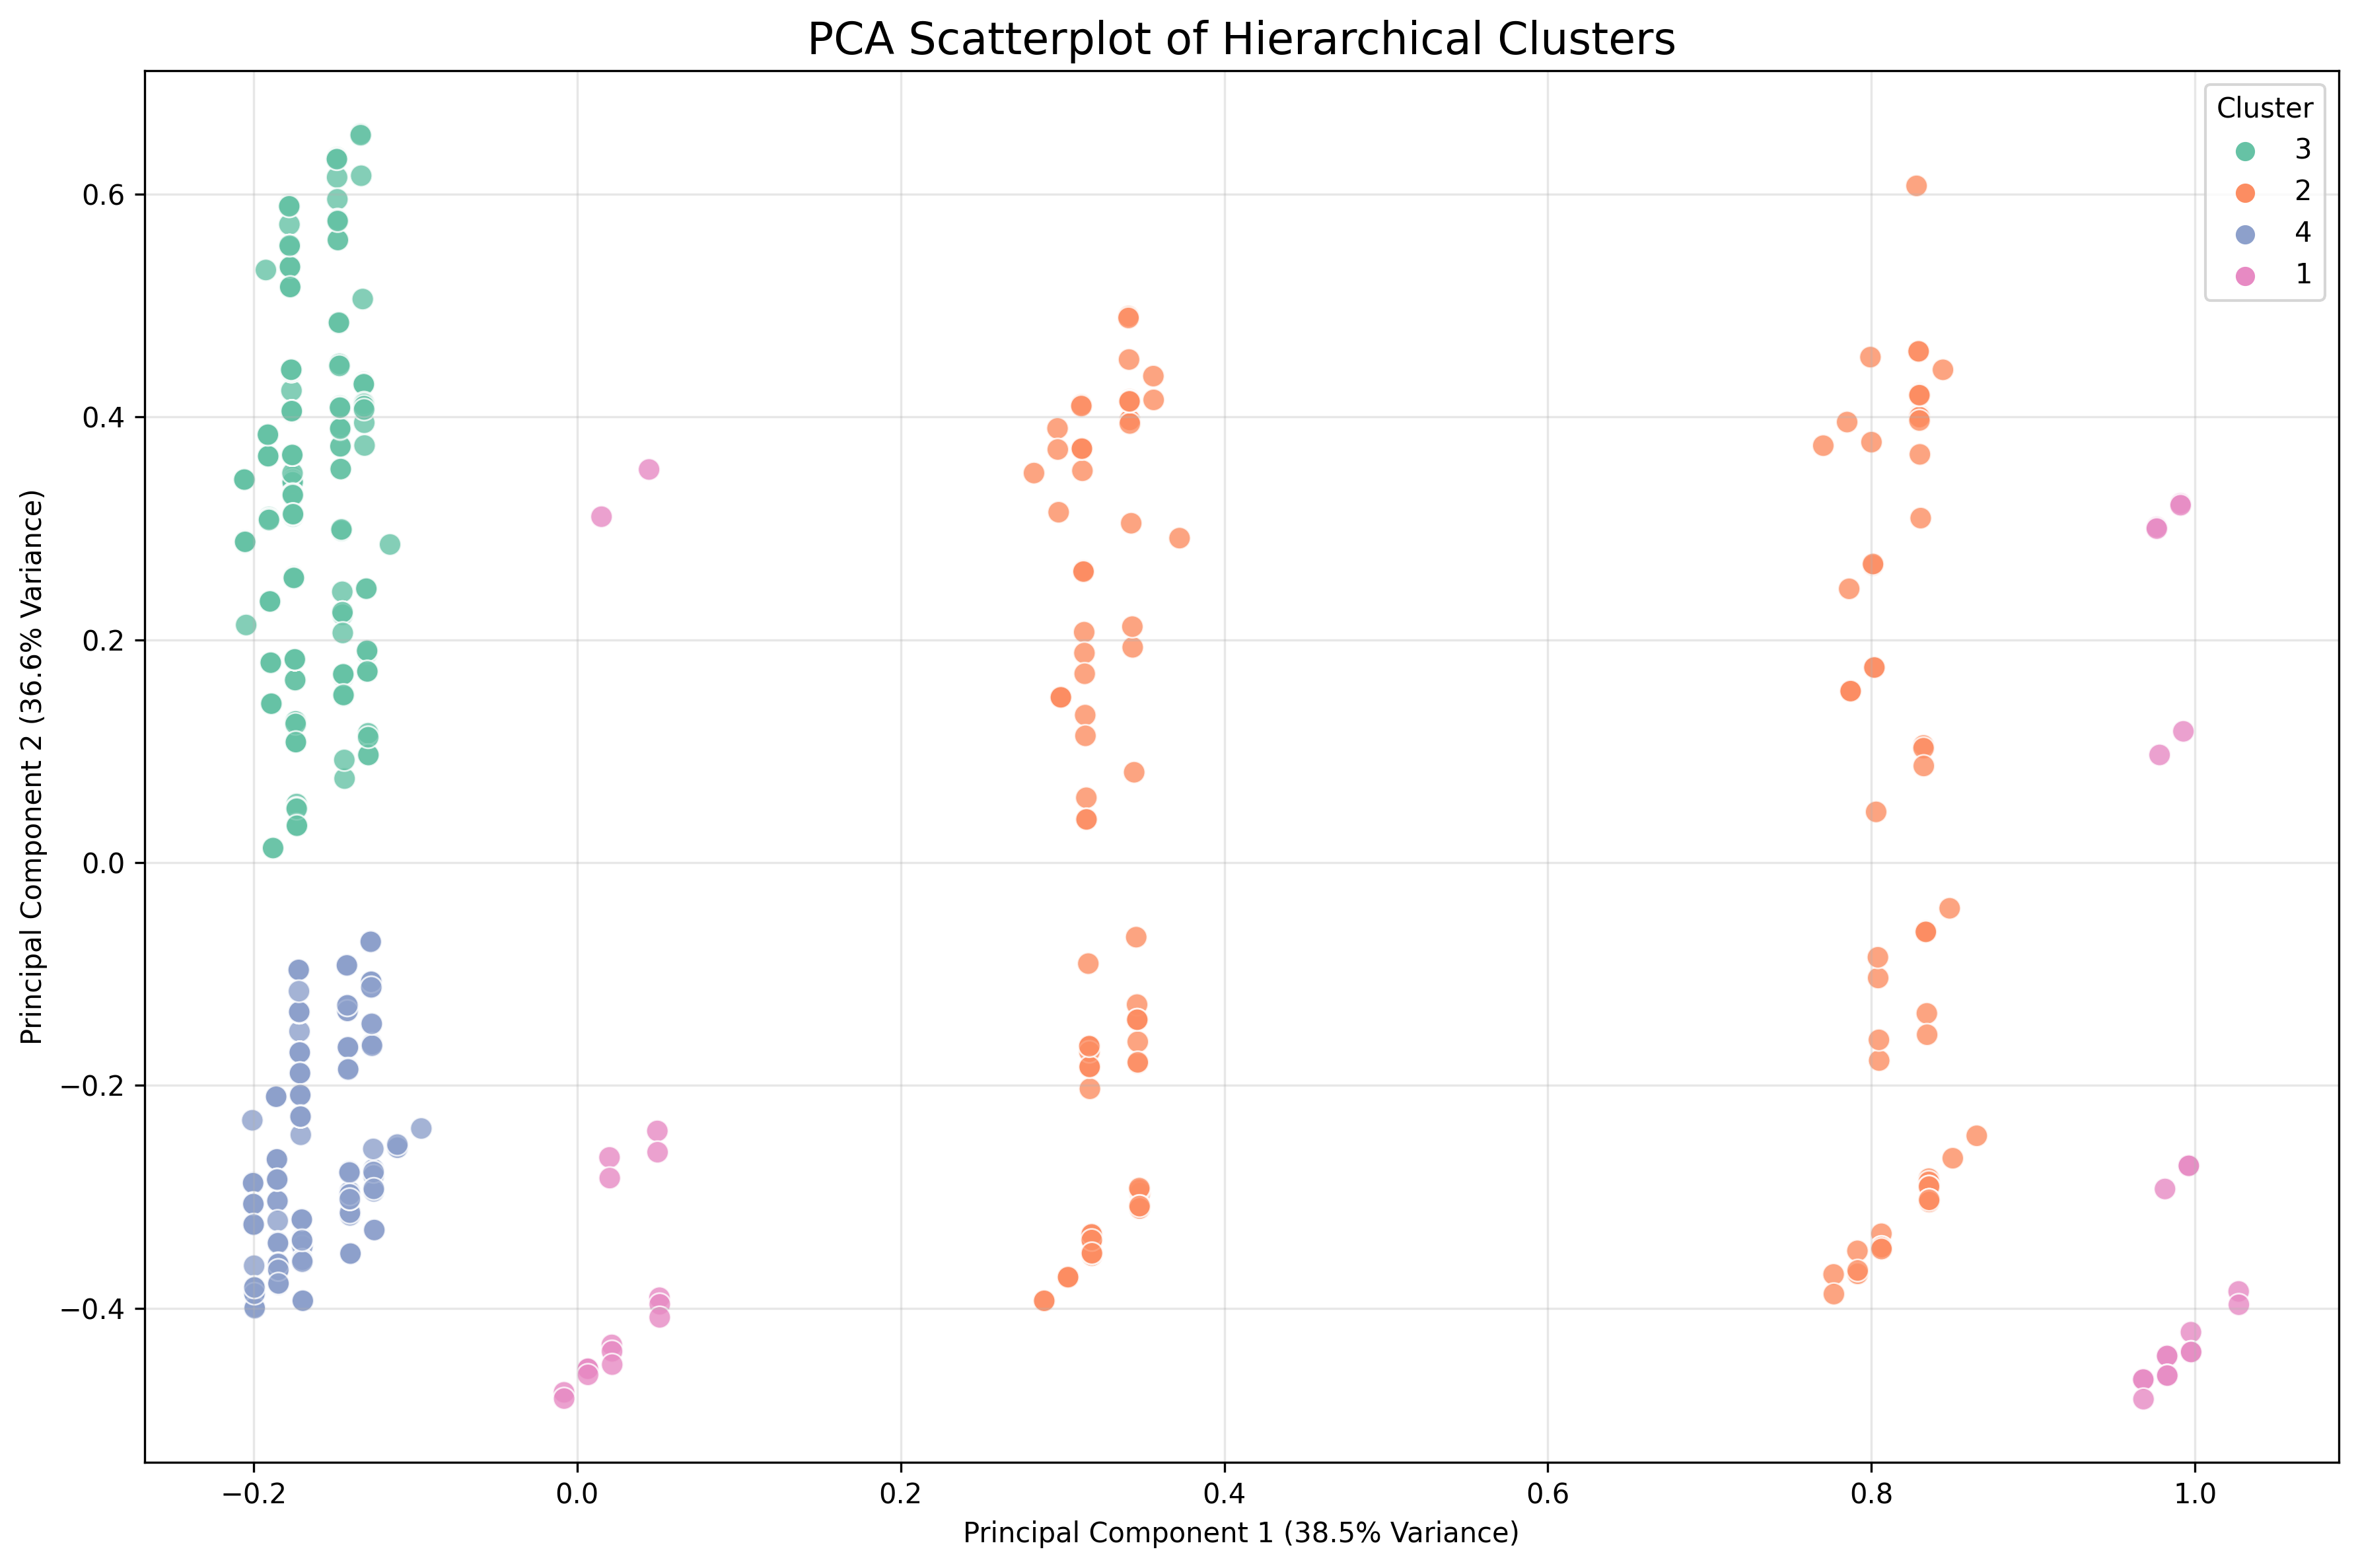

In [12]:
print("PCA scatter plot visualization display...")

display(Image(filename="output/pca_scatter_plot.png"))

### Cluster Size Distribution

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> A cluster size distribution displays the population size of each cluster. Save the image as <b><mark>cluster_size.png</mark></b>. Use <b><mark>display()</mark></b> to render the image for html file output. Do not use an <mark>html image</mark> tag in the markdown, or the image will not print in the html download.</span>
</div>

In [13]:
print("Creating cluster size distribution chart to analyze cluster populations...")

try:
    # Count the number of records in each cluster
    cluster_counts = clustered_data["Cluster"].value_counts().sort_index()

    # Set up the bar chart
    plt.figure(figsize=(10, 6))

    # Create the bars
    colors = ["#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3"]

    bars = plt.bar(
        cluster_counts.index.astype(str),
        cluster_counts.values,
        color=colors,
        edgecolor="black"
    )

    # Add the number of records above each bar
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 5,
            str(int(height)),
            ha="center",
            fontsize=11
        )

    # Add labels and formatting
    plt.title("Cluster Size Distribution", fontsize=16)
    plt.xlabel("Cluster", fontsize=12)
    plt.ylabel("Number of Records", fontsize=12)
    plt.ylim(0, max(cluster_counts.values) * 1.15)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    # Save the chart
    plt.savefig(
        "output/cluster_size.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    print("Cluster size distribution chart saved successfully!")
    print("\nCluster Counts:")
    print(cluster_counts)

except (ValueError, TypeError, OSError) as e:
    print("Error creating cluster size distribution chart:", e)
    raise

Creating cluster size distribution chart to analyze cluster populations...
Cluster size distribution chart saved successfully!

Cluster Counts:
Cluster
1     38
2    201
3    365
4    396
Name: count, dtype: int64


Cluster size distribution visualization display...


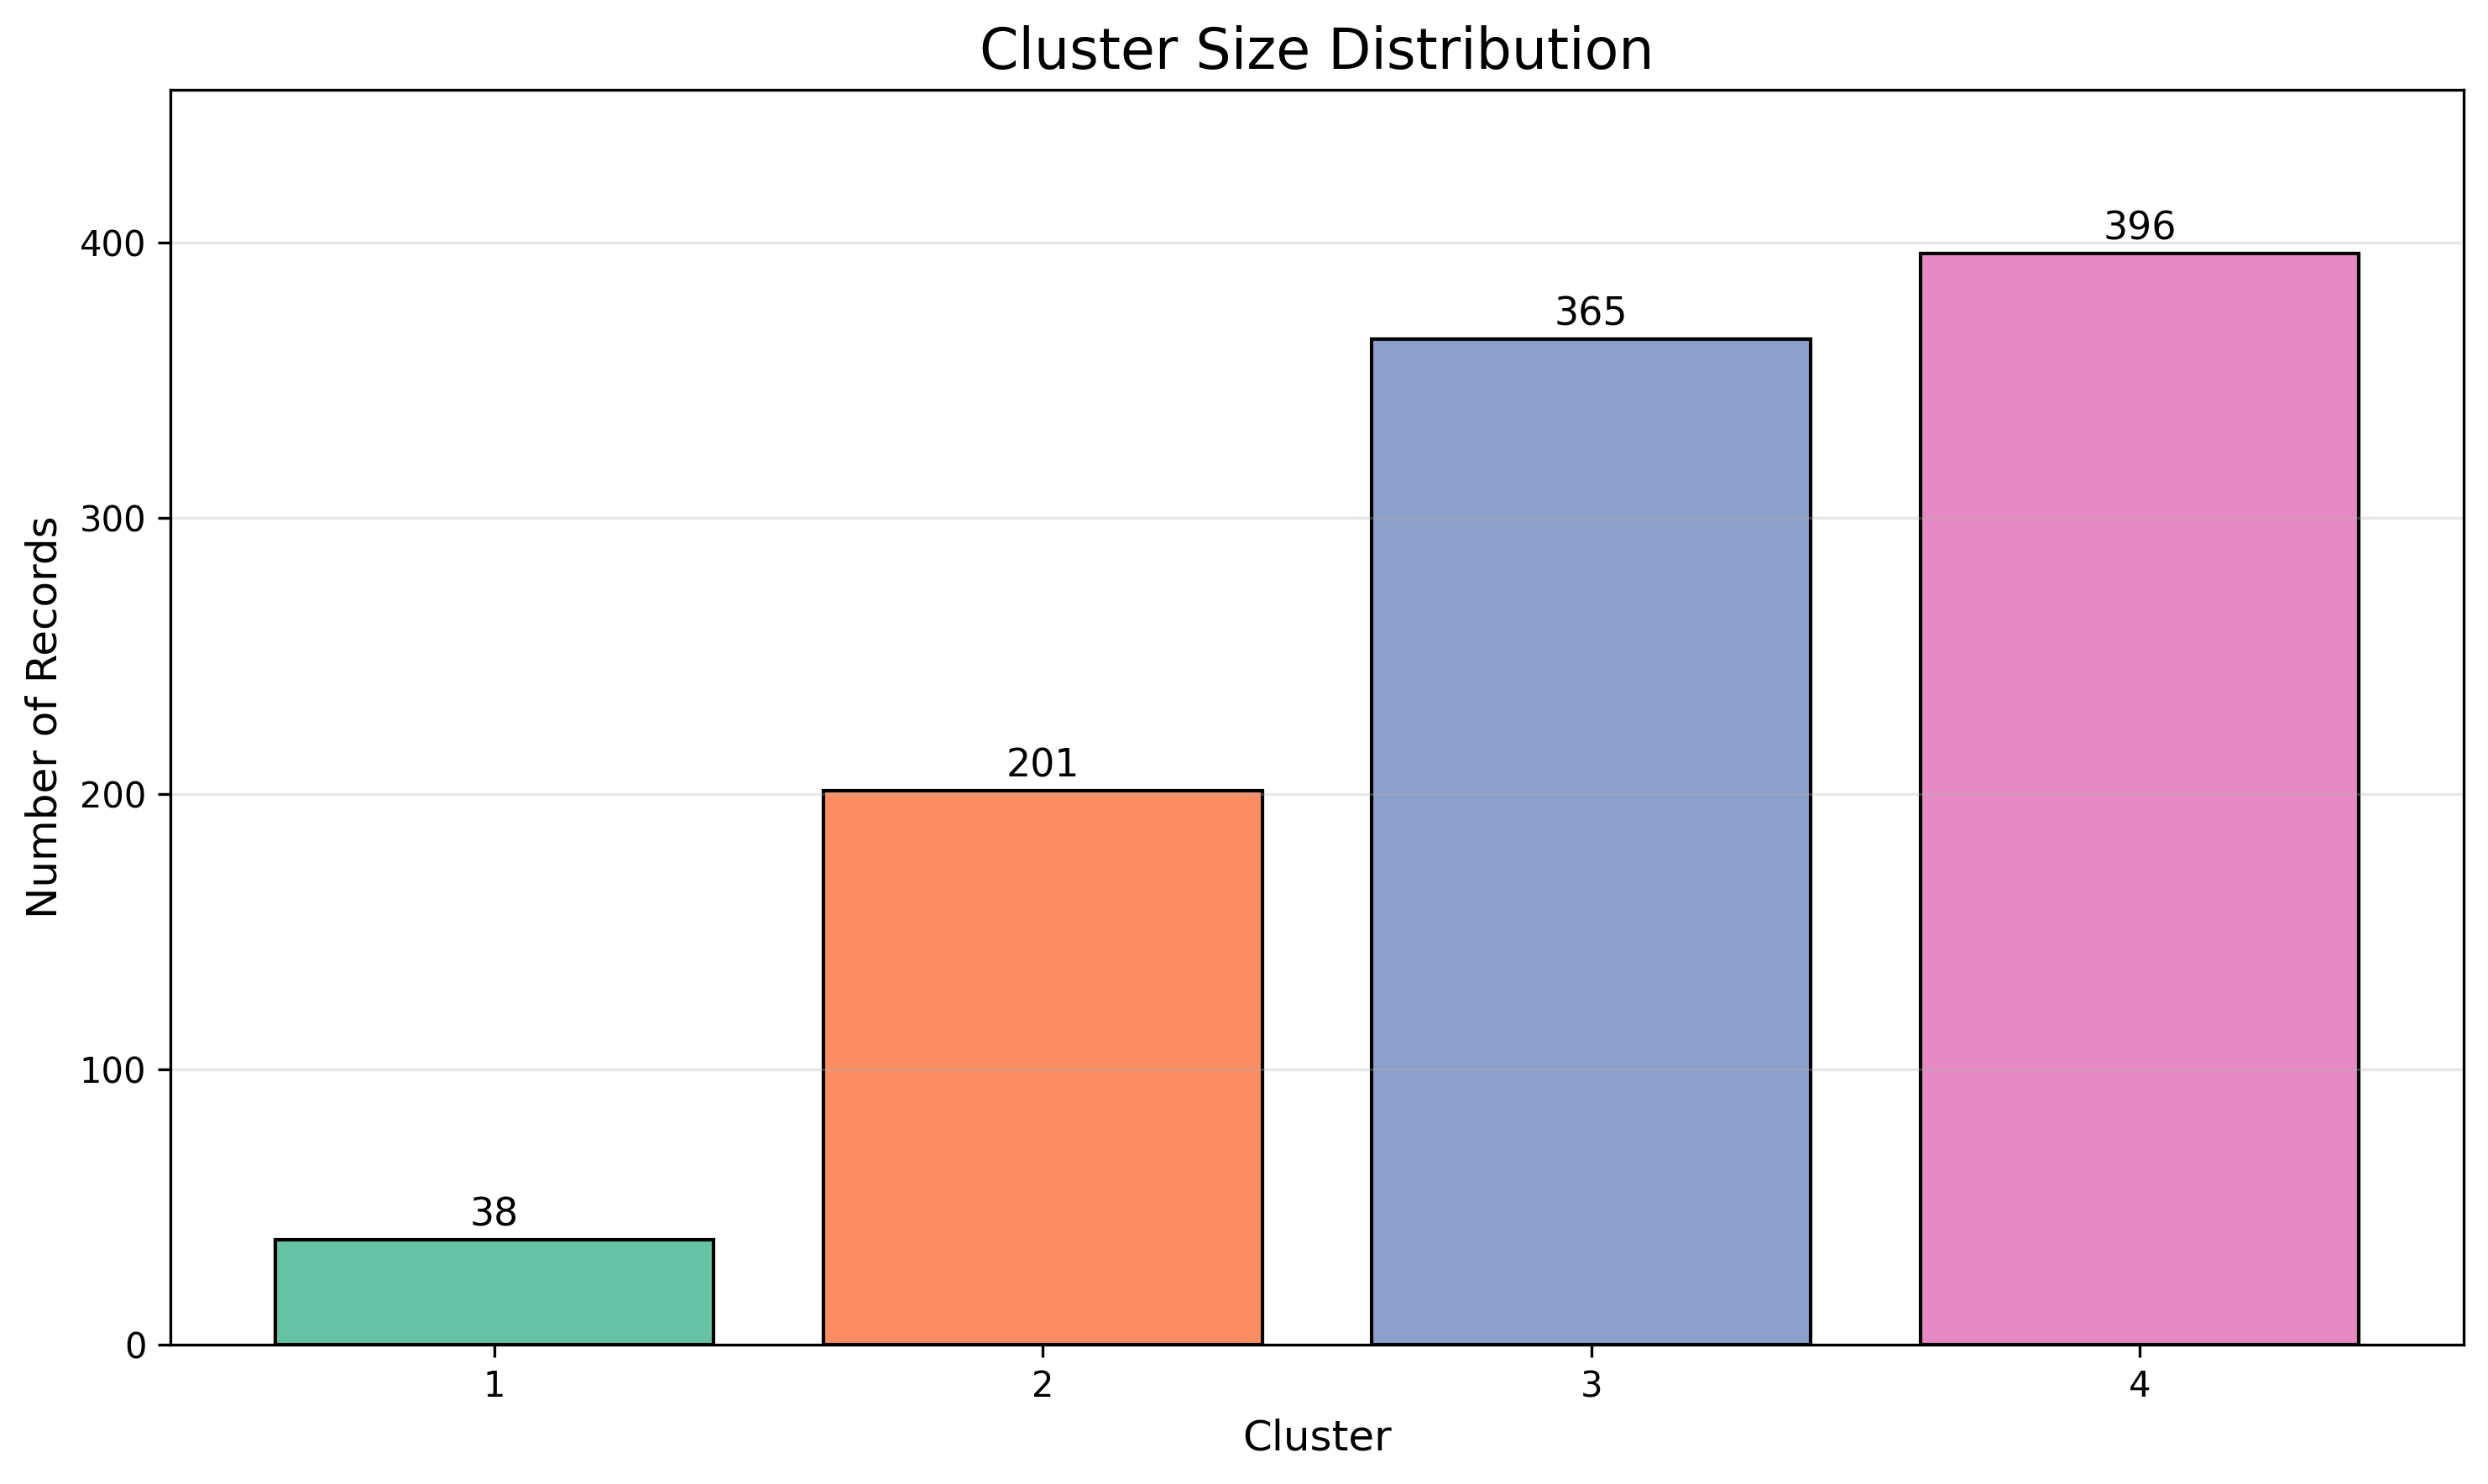

In [14]:

print("Cluster size distribution visualization display...")

display(Image(filename="output/cluster_size.png"))


### Feature Importance Heatmap

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> A feature importance heatmap highlights the average feature values for each cluster. Save the image as <b><mark>heatmap.png</mark></b>. Use <b><mark>display()</mark></b> to render the image for html file output. Do not use an <mark>html image</mark> tag in the markdown, or the image will not print in the html download.</span>
</div>

In [15]:
print("Creating feature importance heatmap to show mean feature values by cluster...")

try:
    # Calculate the average normalized feature values
    # for each of the four clusters
    cluster_means = clustered_data.groupby("Cluster").mean()

    # Create the heatmap
    plt.figure(figsize=(15, 7))

    sns.heatmap(
        cluster_means,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        linewidths=0.5,
        cbar_kws={"label": "Average Normalized Value"}
    )

    # Add chart labels and formatting
    plt.title(
        "Feature Importance Heatmap by Cluster",
        fontsize=16
    )
    plt.xlabel("Numeric Features", fontsize=12)
    plt.ylabel("Cluster", fontsize=12)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    # Save the heatmap
    plt.savefig(
        "output/heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    print("Feature importance heatmap saved successfully!")
    print("\nAverage Feature Values by Cluster:")
    print(cluster_means.round(2))

except (ValueError, TypeError, OSError) as e:
    print("Error creating feature importance heatmap:", e)
    raise

Creating feature importance heatmap to show mean feature values by cluster...
Feature importance heatmap saved successfully!

Average Feature Values by Cluster:
         MAIN  CIPCODE  CREDLEV  IPEDSCOUNT1  IPEDSCOUNT2   
Cluster                                                     
1         0.0     0.77     0.27         0.00         0.00  \
2         1.0     0.60     0.42         0.01         0.01   
3         1.0     0.29     0.36         0.00         0.00   
4         1.0     0.89     0.31         0.00         0.00   

         EARN_COUNT_NWNE_HI_1YR  EARN_COUNT_NWNE_1YR  EARN_COUNT_NWNE_4YR   
Cluster                                                                     
1                          0.01                 0.01                 0.01  \
2                          0.00                 0.00                 0.00   
3                          0.00                 0.00                 0.00   
4                          0.00                 0.00                 0.00   

         

Feature importance heatmap visualization display...


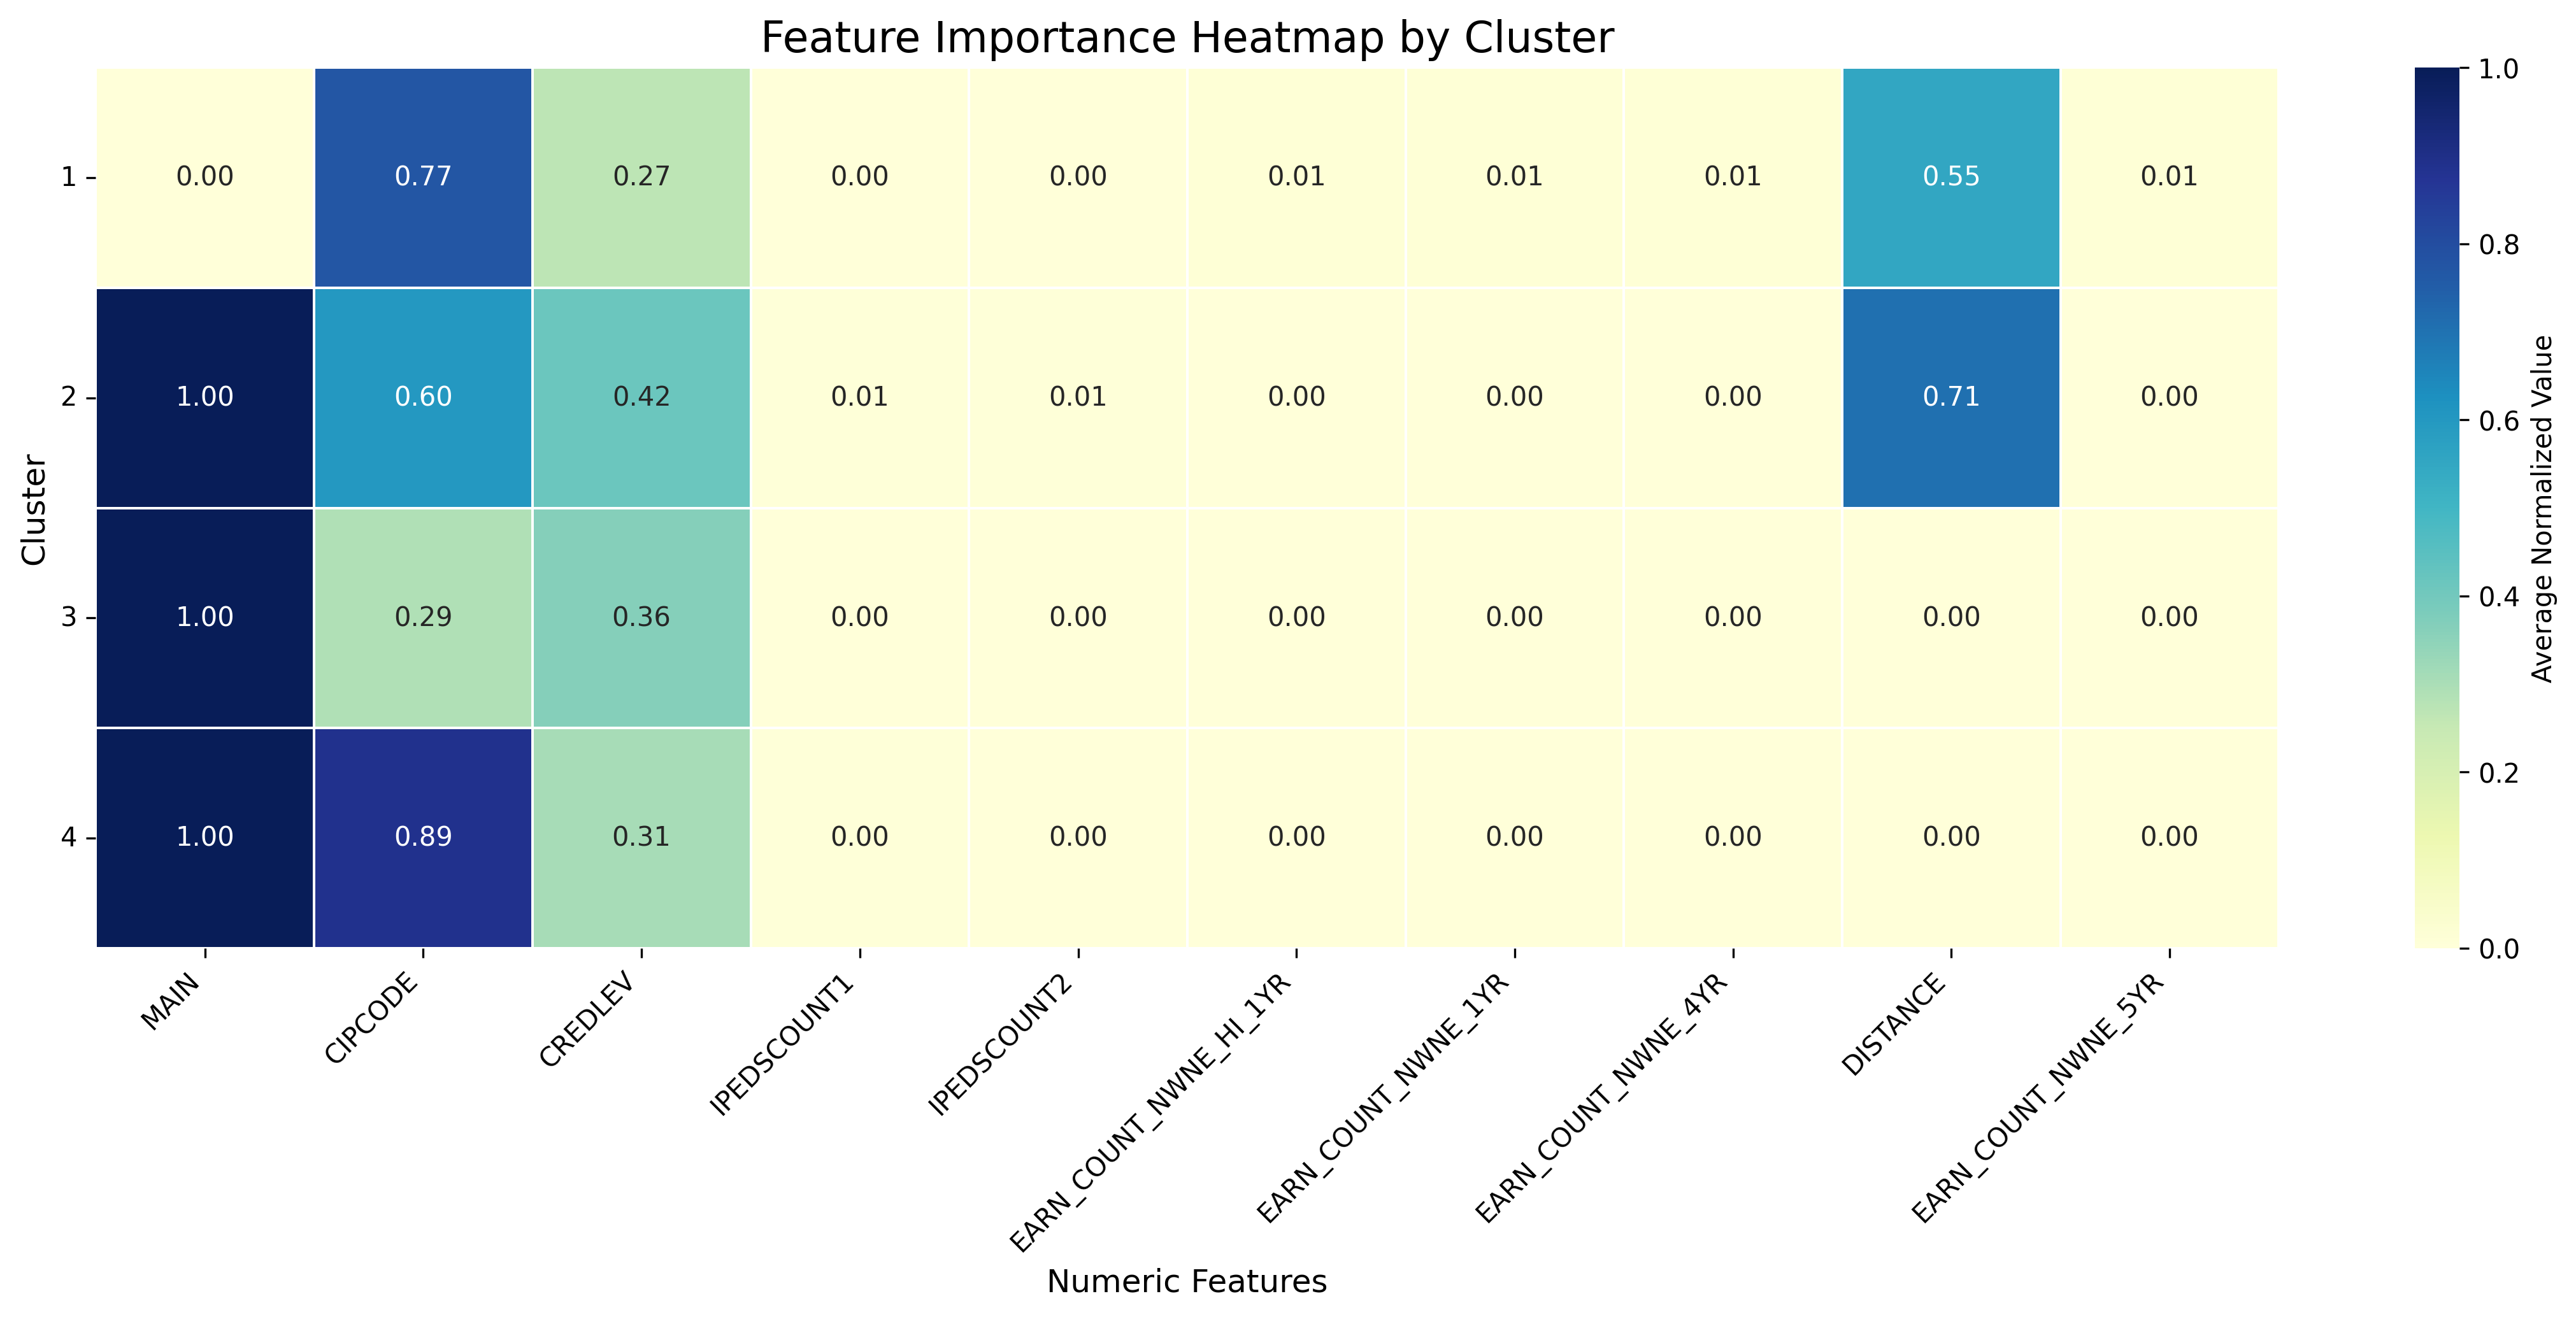

In [16]:
print("Feature importance heatmap visualization display...")

display(Image(filename="output/heatmap.png"))

### Trend Chart

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> A trend chart plots trends in a numeric feature across clusters. Save the image as <b><mark>trend_chart.png</mark></b>. Use <b><mark>display()</mark></b> to render the image for html file output. Do not use an <mark>html image</mark> tag in the markdown, or the image will not print in the html download.</span>
</div>

In [17]:
print("Creating trend chart to analyze a numeric feature across clusters...")

try:
    # Select the feature to compare
    feature = "CREDLEV"

    # Calculate average normalized credential level by cluster
    trend_data = clustered_data.groupby("Cluster")[feature].mean()

    # Create the trend chart
    plt.figure(figsize=(10, 6))

    plt.plot(
        trend_data.index,
        trend_data.values,
        marker="o",
        markersize=9,
        linewidth=2.5,
        color="steelblue"
    )

    # Add data labels
    for cluster, value in trend_data.items():
        plt.annotate(
            f"{value:.2f}",
            (cluster, value),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center"
        )

    # Add titles and formatting
    plt.title(
        "Average Normalized Credential Level by Cluster",
        fontsize=16
    )
    plt.xlabel("Cluster", fontsize=12)
    plt.ylabel("Average Normalized CREDLEV", fontsize=12)
    plt.xticks(trend_data.index)
    plt.ylim(0, max(trend_data.values) * 1.25)
    plt.grid(alpha=0.3)
    plt.tight_layout()

    # Save the chart
    plt.savefig(
        "output/trend_chart.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    print("Trend chart saved successfully!")
    print("\nAverage Credential Level by Cluster:")
    print(trend_data.round(3))

except (ValueError, TypeError, KeyError, OSError) as e:
    print("Error creating trend chart:", e)
    raise

Creating trend chart to analyze a numeric feature across clusters...
Trend chart saved successfully!

Average Credential Level by Cluster:
Cluster
1    0.267
2    0.416
3    0.364
4    0.307
Name: CREDLEV, dtype: float64


Trend chart visualization display...


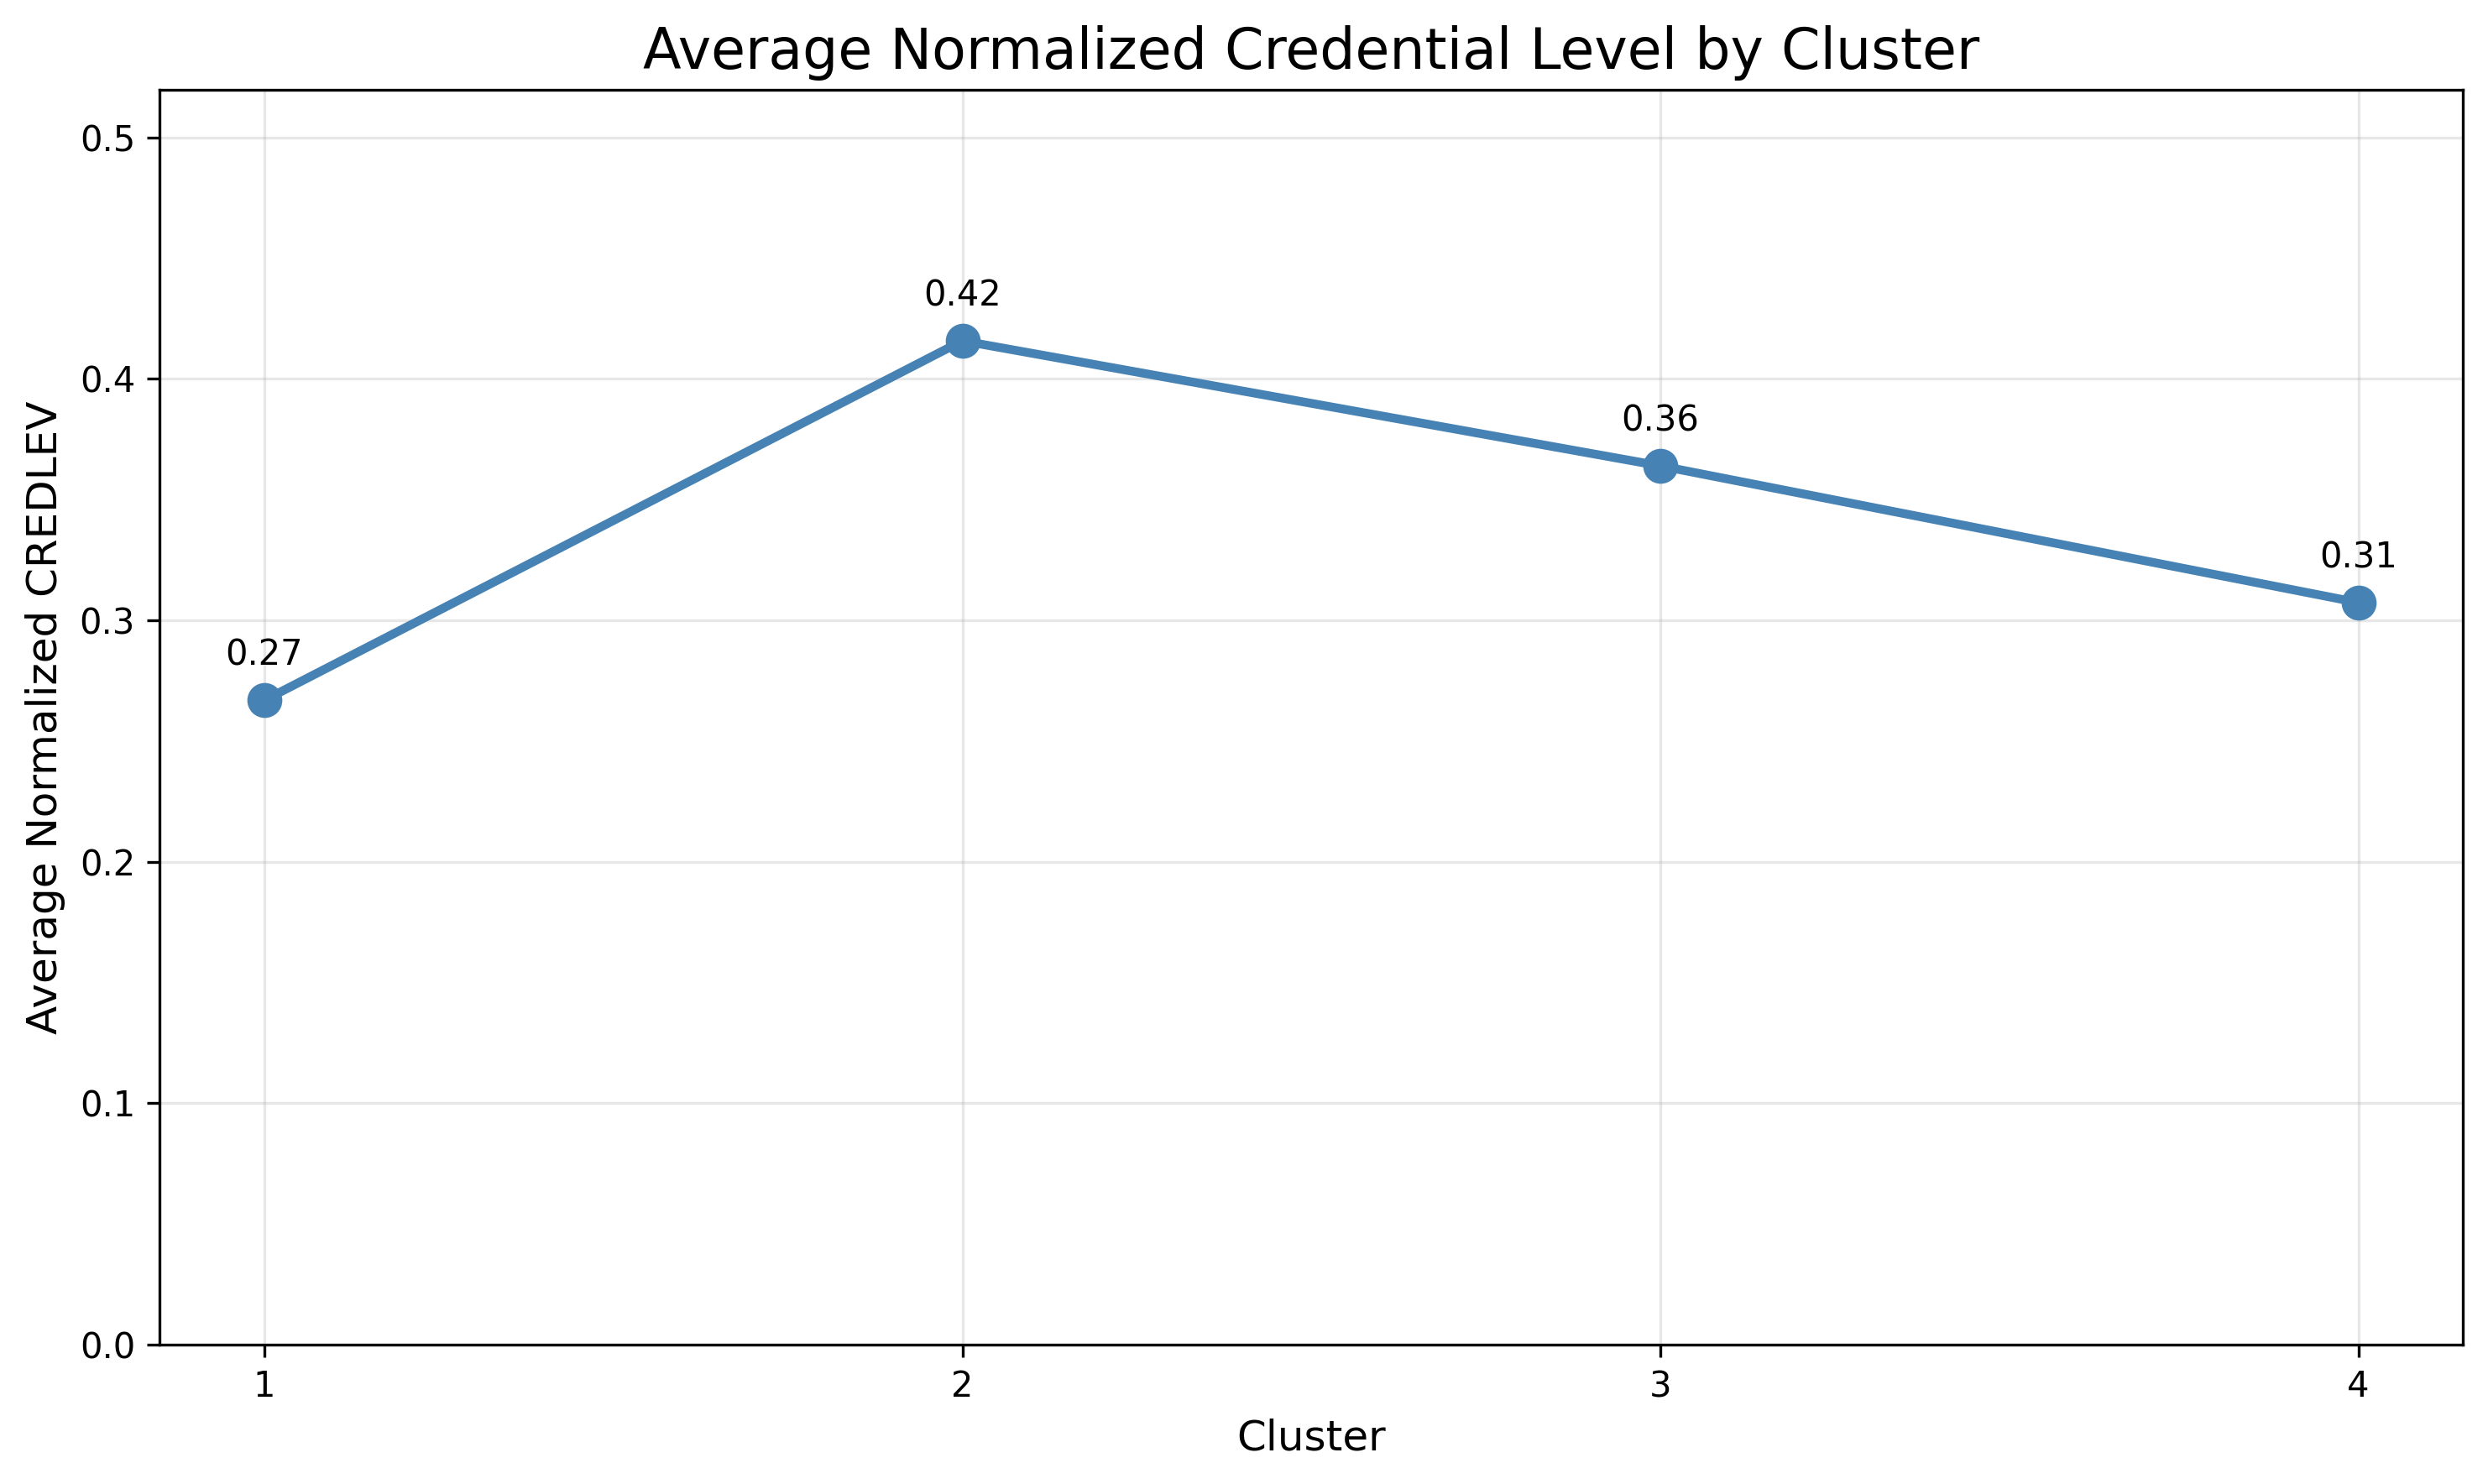

In [18]:
print("Trend chart visualization display...")

display(Image(filename="output/trend_chart.png"))

### Scatter Plot

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hints:</i></b> A scatter plot explores the relationship between two features, grouped by clusters. Save the image as <b><mark>scatter_plot.png</mark></b>. Use <b><mark>display()</mark></b> to render the image for html file output. Do not use an <mark>html image</mark> tag in the markdown, or the image will not print in the html download.</span>
</div>

In [19]:

print("Creating scatter plot of two features...")

try:
    # Select two normalized numeric features
    x_feature = "CIPCODE"
    y_feature = "CREDLEV"

    # Create the scatterplot
    plt.figure(figsize=(12, 8))

    colors = ["#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3"]

    for i, cluster in enumerate(sorted(clustered_data["Cluster"].unique())):
        subset = clustered_data[clustered_data["Cluster"] == cluster]

        plt.scatter(
            subset[x_feature],
            subset[y_feature],
            label=f"Cluster {cluster}",
            color=colors[i],
            s=55,
            alpha=0.7,
            edgecolors="white",
            linewidths=0.3
        )

    # Add chart labels and formatting
    plt.title(
        "Scatterplot of Program Classification and Credential Level",
        fontsize=16
    )
    plt.xlabel("Normalized CIPCODE", fontsize=12)
    plt.ylabel("Normalized CREDLEV", fontsize=12)
    plt.legend(title="Hierarchical Clusters")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    # Save the scatterplot
    plt.savefig(
        "output/scatter_plot.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    print("Scatterplot saved successfully!")

except (ValueError, TypeError, KeyError, OSError) as e:
    print("Error creating scatterplot:", e)
    raise


Creating scatter plot of two features...
Scatterplot saved successfully!


Scatter plot visualization display...


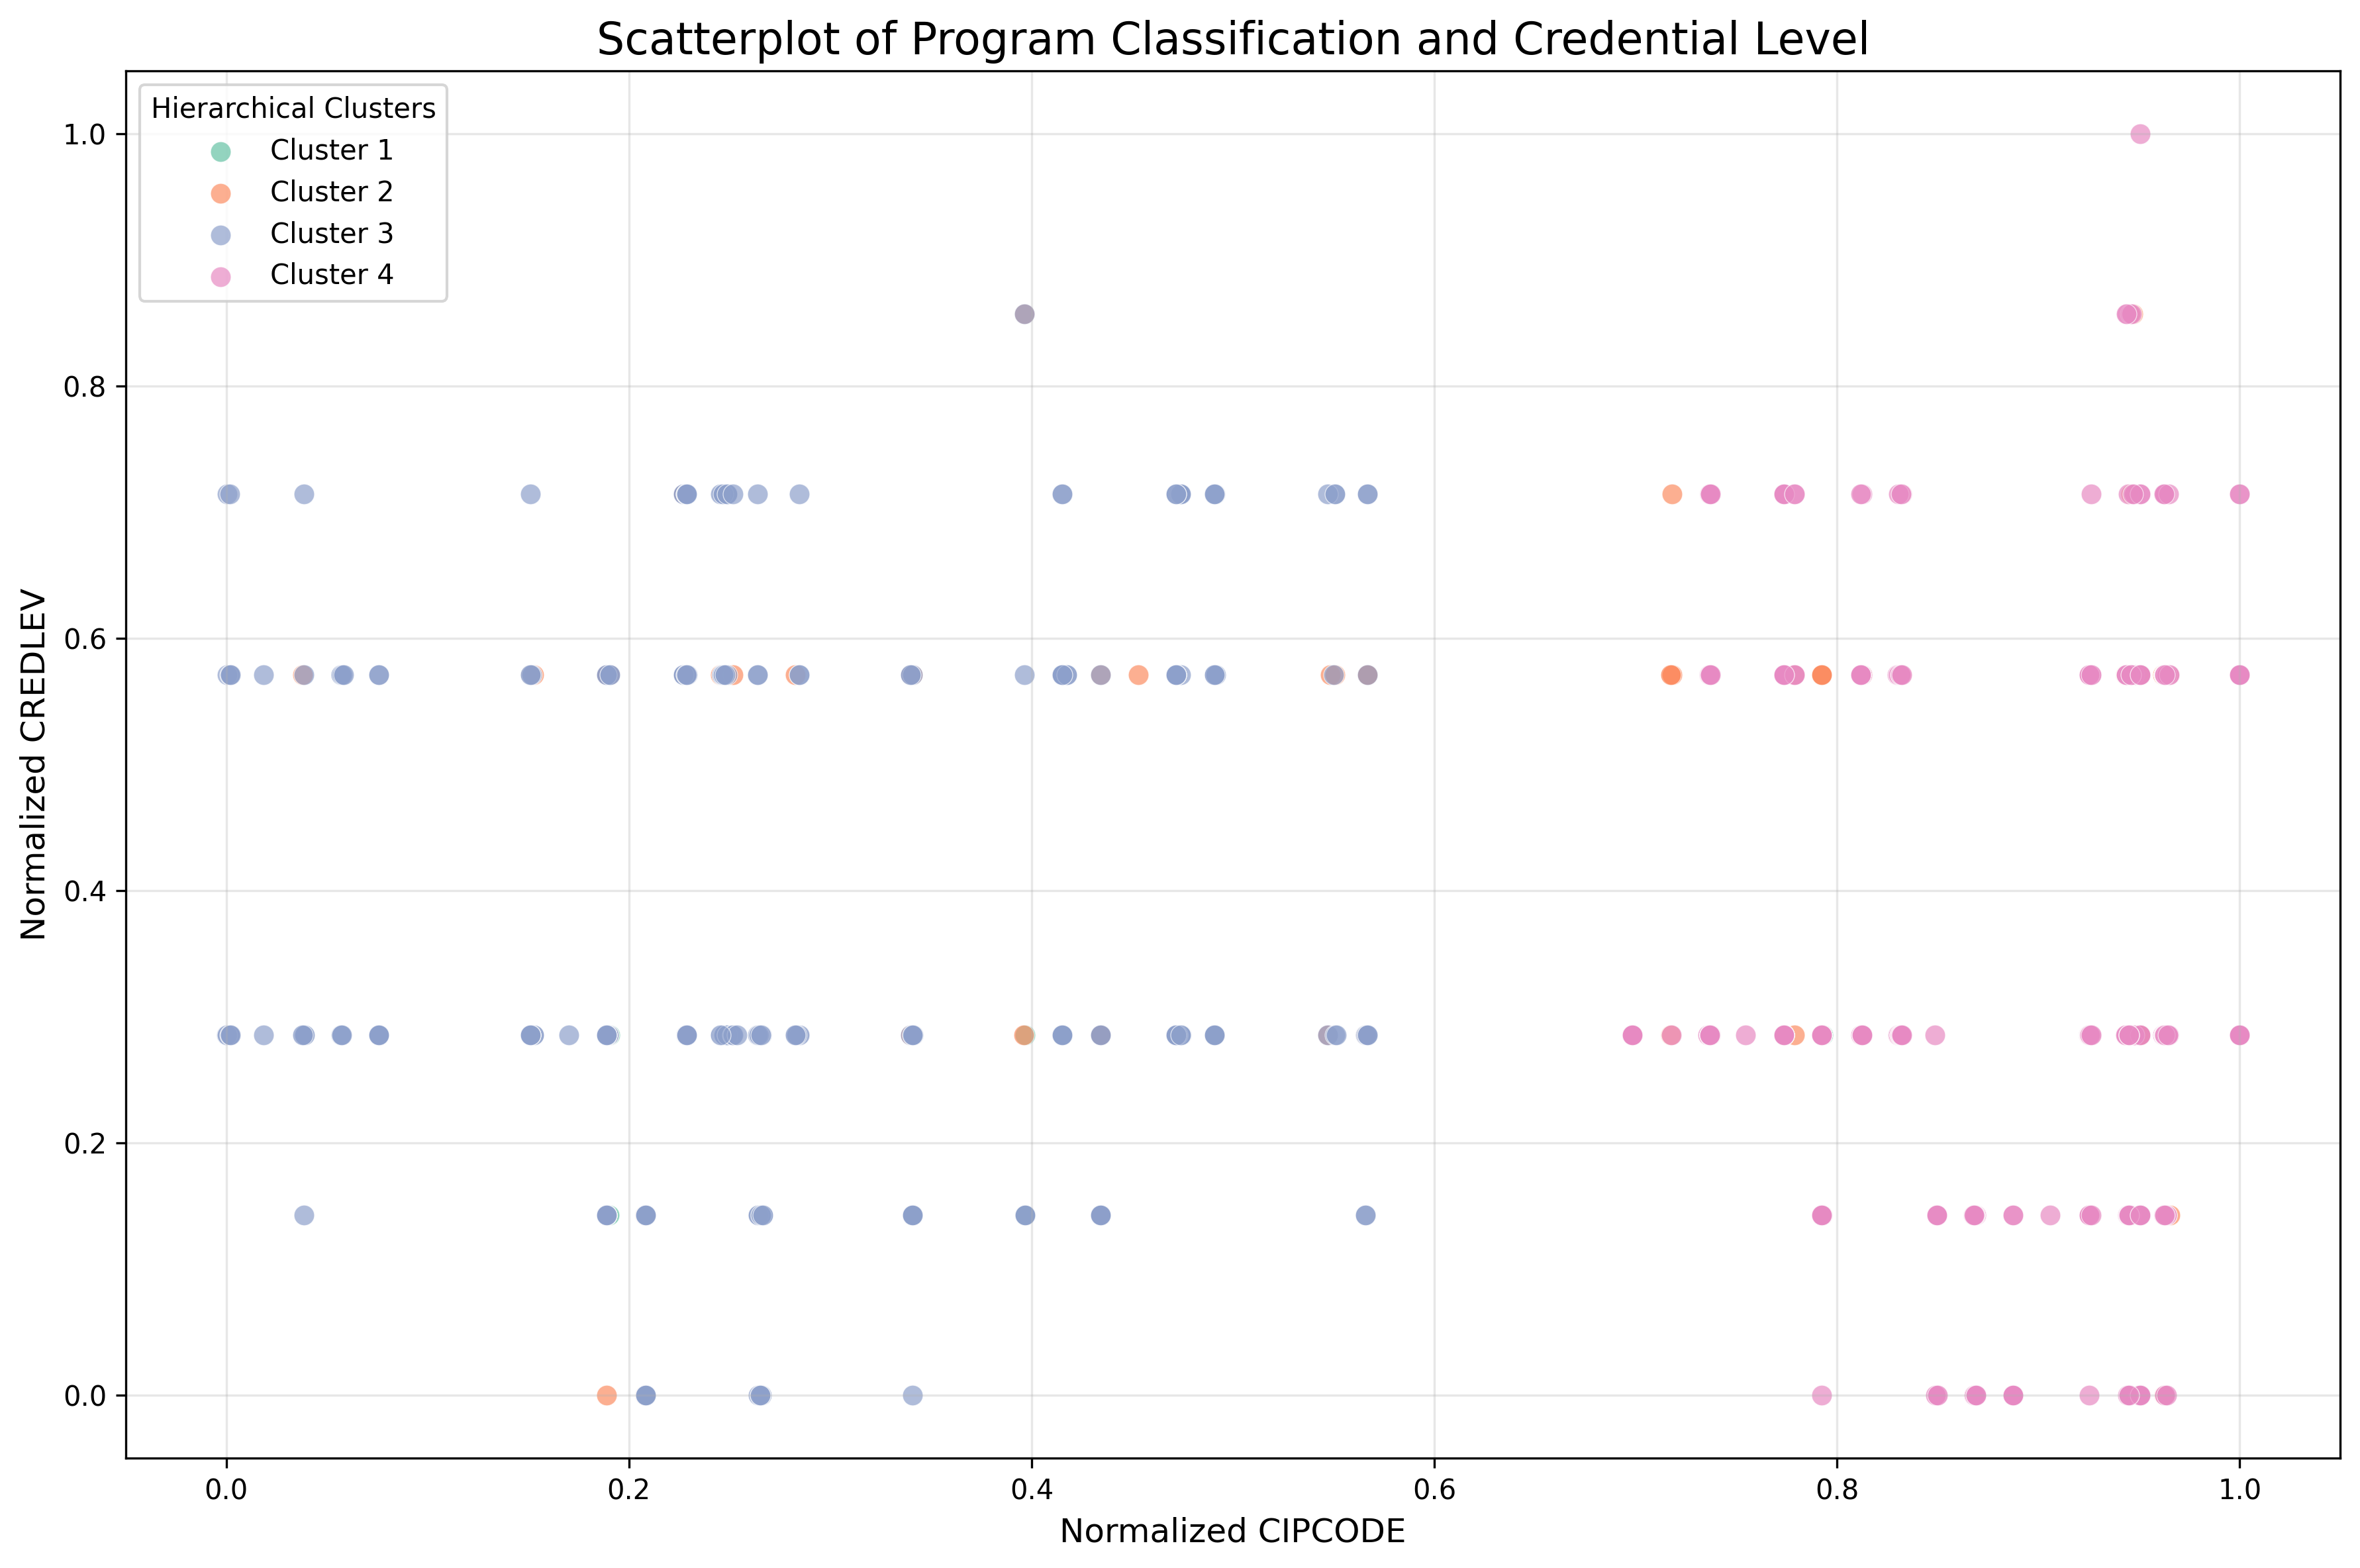

In [20]:
print("Scatter plot visualization display...")

display(Image(filename="output/scatter_plot.png"))

## Part 2: Reflection
<i>This part is to be completed in a word document, using the output above to answer the topics.</i>

### Identify patterns in the data. Consider the following:  
- Are there any clear trends, clusters, or outliers visible in your visualizations? 
- Are certain variables showing consistent behavior or relationships? 
- Are the patterns similar across different visualization types? 

### Draw conclusions from the patterns. Consider the following:  
- Are your conclusions clearly based on the patterns you observed? 
- Are your findings supported by multiple visuals or data points? 

### Explain how the visualizations validate your findings. Consider the following:  
- Are specific chart elements (e.g., color, scale, labels) helping to highlight your findings? 
- Are the insights you found something you could not easily see without the visuals? 

### Write a summary of the visualization choices you made. Include the following:  
- An explanation of the types of charts you used 
- An explanation of the formatting decisions to support visual clarity